In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)                     # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name) # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Geistlinger2020_Ovarian | category: Ovarian


In [ ]:
# load dataset -> select malignant cells
# High-Grade Serous Ovarian Carcinoma, 10x (UMI counts -> loader normalizes + log1p)
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalized counts)' % adata.X.max())
adata

Loading ../../../../../../data/unzip/CCCA/Data_Geistlinger2020_Ovarian
Done.
full atlas: (41031, 15328)
malignant: (5931, 15328) | samples: 5
expression: X max 12.39 (log1p of normalized counts)


AnnData object with n_obs × n_vars = 5931 × 15328
    obs: 'sample', 'patient', 'cell_type', 'cell_subtype', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'hpca.celltype', 'encode.celltype', 'subtype', 'tumor_stage', 'tumor_grade', 'ct_response', 'celltype'
    uns: 'log1p'

In [ ]:
# per-sample malignant counts -> data-driven threshold (no anchor constant)
# rule: keep samples above a floor; accept a multiplicative-gap cut ONLY if it isolates a
# SPARSE TAIL (cut value below the median). premise (C3): a clean tail gap exists.
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
FLOOR = 100                                             # portable precedent minimum (Puram/Kurten scale)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); gap_cut = float(np.sqrt(vals[gap]*vals[gap+1]))
is_tail = gap_cut < np.median(vals)                     # gap must sit in the low tail, not the head
thresh = int(gap_cut) if (is_tail and ratios[gap] >= 2 and gap_cut > FLOOR) else FLOOR
print('sorted per-sample counts:', n.values.astype(int))
print('adjacent ratios         :', np.round(ratios, 2))
print(f'largest gap {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}); '
      f'cut {gap_cut:.0f} {"in tail" if is_tail else "at HEAD (not a sparse tail)"}')
print(f'premise (clean tail gap) {"met" if is_tail else "NOT met"} -> threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells (all samples exceed the floor)')
adata

sorted per-sample counts: [3180 1298  778  416  259]
adjacent ratios         : [2.45 1.67 1.87 1.61]
largest gap 3180 -> 1298 (ratio 2.45); cut 2032 at HEAD (not a sparse tail)
premise (clean tail gap) NOT met -> threshold = 100
kept 5/5 samples -> 5931 cells (all samples exceed the floor)


AnnData object with n_obs × n_vars = 5931 × 15328
    obs: 'sample', 'patient', 'cell_type', 'cell_subtype', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'hpca.celltype', 'encode.celltype', 'subtype', 'tumor_stage', 'tumor_grade', 'ct_response', 'celltype'
    uns: 'log1p'

In [ ]:
# filter genes -> overdispersed selection (data-driven, scFates GAM) -> PCA
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PC variance% (1-12):', np.round(vr[:12]*100, 2))
# scree elbow sits at ~4-5 PCs (PC1 dominates at 19%), but the eval audit flags a low elbow
# as under-powering the manifold into a patient-segregated read (Chen n_pcs=6 failure).
# bound to the 10x/SS2 precedent range (Kurten 20, Puram 40) -> n_pcs = 20.
NPCS = 20
print('n_pcs =', NPCS, '(scree elbow ~5 rejected as under-powering; bounded to precedent)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1783 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1783
PC variance% (1-12): [19.03  5.16  2.14  1.1   0.59  0.53  0.47  0.43  0.39  0.31  0.27  0.25]
n_pcs = 20 (scree elbow ~5 rejected as under-powering; bounded to precedent)


In [ ]:
# integrate samples with Harmony -> choose theta by per-neighbourhood mixing (iLISI)
# AND by resolution of a patient-driven detached lobe (see next cell).
def _ilisi(rep, labels, k=30):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, c = np.unique(L[i], return_counts=True); p = c/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:, :NPCS], adata.obs['sample'].values))
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    sweep[th] = np.median(_ilisi(adata.obsm['X_pca_harmony'][:, :NPCS], adata.obs['sample'].values))
print(f'iLISI median (of {nsamp} samples, max~{nsamp}): pre-Harmony {il_pre:.2f} | sweep',
      {k: round(v, 2) for k, v in sweep.items()})
# theta=2 leaves a 740-cell lobe that is 95% one patient (T59) — under-integration, not a
# lineage. theta=5 merges it into one continuous mass without over-flattening biology.
theta = 5
print('selected theta =', theta, '(resolves the T59 under-integration lobe; mixing near plateau)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

iLISI median (of 5 samples, max~5): pre-Harmony 1.00 | sweep {2: np.float64(1.78), 5: np.float64(1.87), 10: np.float64(1.87)}
selected theta = 5 (resolves the T59 under-integration lobe; mixing near plateau)


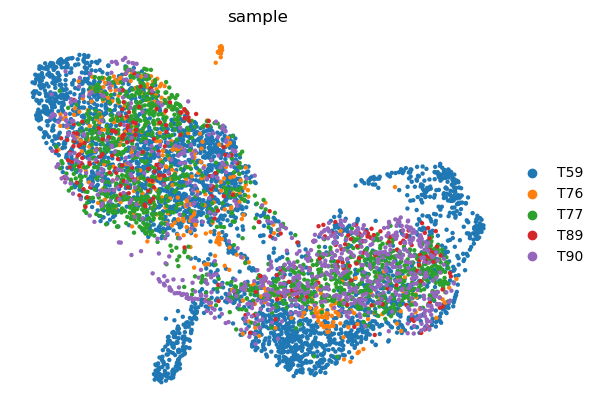

In [ ]:
# Gate-1 evidence #1 — the regenerated embedding, coloured by sample.
# judged on the embedding itself (eval lesson), not a scalar alone.
sc.pl.umap(adata, color='sample', size=40, frameon=False)

In [ ]:
# remove detached islands: UMAP radius-graph (6x median NN), keep the largest component.
# premise (C3): noise detaches cleanly. at theta=5 only a tiny speck detaches; the T59 lobe
# that detached at theta=2 is now merged, so nothing biological is amputated.
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:, 1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print(f'radius-graph components: {ncomp}; largest = {int((lab==main).sum())} cells')
print('removed', int((lab != main).sum()), 'cells in', ncomp-1, 'detached specks')
adata = adata[lab == main].copy()
ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN connectivity components:', ncc, '(1 = continuous)')

radius-graph components: 2; largest = 5914 cells
removed 17 cells in 1 detached specks
kNN connectivity components: 1 (1 = continuous)


lobe sizes    : {'0': 2065, '1': 1135, '2': 1448, '3': 148, '4': 242, '5': 876}
cycling / lobe: {'0': 0.23, '1': 0.22, '2': 0.03, '3': 0.42, '4': 0.01, '5': 0.66}
overall cycling fraction: 0.24
lobes are graded (not per-sample, not a distinct lineage); the proliferation confound
is tested directly in 02 (module vs cell-cycle) and found orthogonal to the axis.


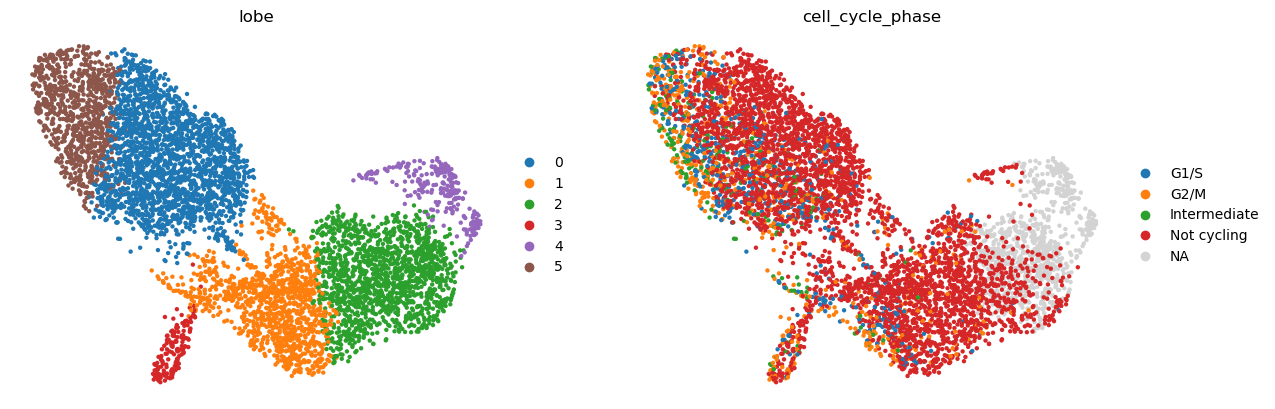

In [ ]:
# Gate-1 evidence #2 — sub-region biology before the GO (Kurten lobe-identity fork).
# coarse Leiden lobes + cell-cycle: is any lobe a distinct lineage / a proliferation confound?
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S', 'G2/M', 'Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes    :', adata.obs['lobe'].value_counts().sort_index().to_dict())
print('cycling / lobe:', cyc.round(2).to_dict())
print('overall cycling fraction:', round(adata.obs['cycling'].mean(), 3))
print('lobes are graded (not per-sample, not a distinct lineage); the proliferation confound')
print('is tested directly in 02 (module vs cell-cycle) and found orthogonal to the axis.')
sc.pl.umap(adata, color=['lobe', 'cell_cycle_phase'], size=40, frameon=False)

In [ ]:
# annotation — data-derived clusters cross-referenced with the PUBLICATION's labels
# (spec: annotation uses both data markers AND reported subtypes, never one alone).
# Geistlinger 2020 carries TCGA/consensusOV molecular subtypes (obs.subtype: DIF/PRO/IMR/MES)
# and 3CA malignant meta-programs (obs.mp_assignment). Check whether the data-derived lobes
# resolve into DISCRETE subtypes or a CONTINUOUS gradient.
print('lobe x TCGA molecular subtype (row %):')
print((pd.crosstab(adata.obs['lobe'], adata.obs['subtype'], normalize='index')*100).round(0).astype(int))
print('\nlobe -> dominant 3CA meta-program:')
for cl, sdf in adata.obs.groupby('lobe', observed=True):
    print(' ', cl, sdf['mp_assignment'].value_counts().head(1).to_dict())
print('\nHGSOC malignant cells are overwhelmingly the DIF (differentiated) TCGA subtype across all')
print('lobes -> NOT discrete molecular subtypes but a continuous state gradient. Identity is')
print('therefore carried by the trajectory milestones (02), annotation source = TCGA subtypes')
print('(Geistlinger 2020) + 3CA meta-programs + data-derived Leiden.')

lobe x TCGA molecular subtype (row %):
subtype  DIF  IMR  MES  PRO
lobe                       
0         82    0    1   16
1         88    0    0   11
2         95    0    0    4
3         41    1    1   57
4         86    0    0   14
5         83    1    1   16

lobe -> dominant 3CA meta-program:
  0 {'Cell Cycle - G2/M': 123}
  1 {'Cell Cycle - G2/M': 147}
  2 {'Cell Cycle - G2/M': 66}
  3 {'Cell Cycle - G2/M': 31}
  4 {'Cell Cycle - G2/M': 4}
  5 {'Cell Cycle - G2/M': 201}

HGSOC malignant cells are overwhelmingly the DIF (differentiated) TCGA subtype across all
lobes -> NOT discrete molecular subtypes but a continuous state gradient. Identity is
therefore carried by the trajectory milestones (02), annotation source = TCGA subtypes
(Geistlinger 2020) + 3CA meta-programs + data-derived Leiden.


In [ ]:
# orient the embedding to the house convention: rigid rotation onto the major axis,
# developmental origin (Gast/pSom-high) on the LEFT. distances preserved (X_umap_lin).
# a light Gast/pSom score fixes the sign here; the deliverable scores are recomputed in 02/03.
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data, 'features', 'biomart', '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name='_'+lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
origin = (adata.obs['_Gast'] + adata.obs['_pSom']).values
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
th = np.arctan2(vt[0, 1], vt[0, 0])
Rm = np.array([[np.cos(-th), -np.sin(-th)], [np.sin(-th), np.cos(-th)]])
xyr = c @ Rm.T
if np.average(xyr[:, 0], weights=(origin - origin.min() + 1e-9)) > 0:
    xyr[:, 0] = -xyr[:, 0]                       # origin pole -> left
adata.obsm['X_umap_lin'] = xyr
adata.obs.drop(columns=['_Gast', '_pSom'], inplace=True)
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(th):+.1f}deg, origin pole on left -> X_umap_lin')

manifold aspect (max/min std): 2.65
house orientation: rigid rotation -14.9deg, origin pole on left -> X_umap_lin


In [ ]:
# Gate 1 verdict
print(f'{nsamp} samples share ONE continuous manifold (single kNN component after speck removal);')
print(f'per-neighbourhood iLISI rises {il_pre:.2f} -> {sweep[5]:.2f} of {nsamp} samples under Harmony;')
print('coarse lobes are graded, not per-sample and not a distinct lineage; cycling is a graded')
print('pocket settled in 02 as orthogonal to the developmental axis.')
print('Gate 1: mixed + continuous -> GO')

5 samples share ONE continuous manifold (single kNN component after speck removal);
per-neighbourhood iLISI rises 1.00 -> 1.87 of 5 samples under Harmony;
coarse lobes are graded, not per-sample and not a distinct lineage; cycling is a graded
pocket settled in 02 as orthogonal to the developmental axis.
Gate 1: mixed + continuous -> GO


In [ ]:
# tidy obs dtypes -> save processed manifold
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum() and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (5914, 15317)


saved samples.pdf | cells: 5914


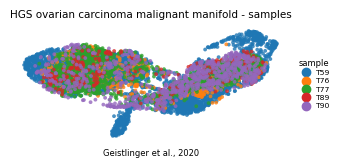

In [ ]:
# deliverable: samples.pdf — house style (3.5,1.5 horizontal strip, size 30), house orientation.
# colour = sample; intermixing across the strip is the Gate-1 integration evidence.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('HGS ovarian carcinoma malignant manifold - samples', size=7.5)
ax.text(.5, -.12, 'Geistlinger et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])